Задание: 

1. Вам необходимо использовать для обучения свой набор данных, который вы должны собрать сами и загрузить его в колаб через доступ к вашему гугл-диску. Классов должно быть 7, количество экземпляров в классе вариативно.

2. Точность должна быть не меньше 85. Метрику выбираете сами. Метрика должна быть изображена на графике, как в примере из лекции.

3. Чтобы загрузить изображение, вы можете использовать Gradio или просто загружать из консоли.

4. Необходимо отобразить топологию вашей нейронной сети с использование метода model.summary().

Прикрепите файл в формате .ipynb. 

Балл за задание: 3.

В этом ноутбуке будет реализована простая модель классификации изображений, с использованием Gradio и Keras. Модель классификации изображений будет классифицировать изображения различных цветов по маркированным классам.

Gradio — это библиотека машинного обучения, которая создает интерактивное приложение для обученной модели машинного обучения. Gradio создает пользовательские интерфейсы (UI), которые позволяют пользователю взаимодействовать с обученной моделью машинного обучения. Она создает веб-интерфейс, который позволяет пользователю тестировать обученную модель и просматривать результаты прогнозирования. Она легко интегрирует пользовательский интерфейс прямо в блокнот Python (либо блокнот Jupyter, либо блокнот Google Colab) без необходимости устанавливать какие-либо зависимости.

Gradio напрямую работает с популярными библиотеками машинного обучения, такими как Sckit-learn, Tensorflow, Keras, PyTorch и Hugging Face Transformers.

In [1]:
!pip install gradio

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 30.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.5/71.5 KB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.9/56.9 KB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 35.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.0/107.0 KB 7.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.7/140.7 KB 4.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.5/84.5 KB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 KB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 KB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.4/66.4 KB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━

Импорт библиотеки Gradio:

In [2]:
import gradio as gr

Ипортируем библиотечки:

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import os
import PIL
import tensorflow as tf

from tensorflow import keras # Импорт keras
from tensorflow.keras import layers # испорт словев keras

numpy нужен для преобразования набора данных изображения в массив.

os позволяет использовать функции операционной системы прямо в Google Colab.

Matplotlib - графическая библиотека. Она нужна для визуализации некоторых изображений в Google Colab.

tensorflow необходим для построения модели классификации изображений. Здесь импортируются слои Keras из TensorFlow. Они используются для инициализации сверточной нейронной сети (CNN).

pillow (PIL)используется для обработки и предварительной обработки изображений в наборе данных.

pathlib используется для указания пути к набору данных, чтобы можно было загрузить набор данных изображений в Google Colab.

Путь к набору данных:

In [4]:
import pathlib
flowers_dataset_path = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

# Загрузка набора данных в Google Colab и извлечение

loaded_data = tf.keras.utils.get_file('flower_photos', origin=flowers_dataset_path, untar=True)
loaded_data = pathlib.Path(loaded_data)

228813984/228813984 [==============================] - 4s 0us/step


Набор данных изображений имеет пять помеченных классов цветов. Помеченные классы цветов: «тюльпаны», «одуванчик», «маргаритки», «подсолнухи» и «розы». Извлечем розы:

/root/.keras/datasets/flower_photos/roses/4356781875_92c5cd93c0.jpg


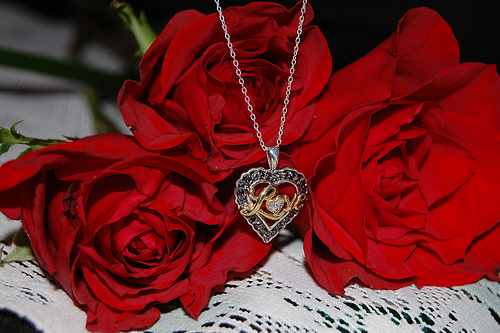

In [5]:
roses = list(loaded_data.glob('roses/*'))
print(roses[0]) # отображение выбранного изображения
PIL.Image.open(str(roses[0])) # отображение 1 изображения

Задаем размеры изображения:

In [6]:
# задание высоты и ширины изображений, которые будут подаваться в нейронную сеть

set_height,set_width = 180,180 # Входное изображение будет иметь размер 180 на 180 пикселей.
batch_size = 32 # размер партии, которая подается на обучение в течение каждой эпохи

Настройка тренировочного набора

Необходимо выбрать изображения из набора данных для обучения модели. Сверточная нейронная сеть будет учиться на этих изображениях.

Будем использовать keras.preprocessing для установки тренировочного набора.

In [7]:
training_images = tf.keras.preprocessing.image_dataset_from_directory(
  loaded_data,
  subset="training",
  validation_split=0.25,
  seed=123,
  image_size=(set_height, set_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 2753 files for training.


В приведенном выше выводе: весь набор данных содержит 3670 изображений, а на 2753 изображених будет обучаться CNN.

В функции выше мы используем разделение исходный набор на 0.25, это означает, что на 75% набора данных будет обучаться CNN. Также функция имеет следующие дополнительные параметры:

seed - воспроизведение изображения одинаковых размеров в каждую эпоху.

image_size - размеры изображения (180 * 180), которые мы установили ранее.

batch_size - размер пакета, который мы установили ранее.

Настройка проверочного набора

In [8]:
validation_images = tf.keras.preprocessing.image_dataset_from_directory(
  loaded_data,
  subset="validation",
  validation_split=0.25,
  seed=123,
  image_size=(set_height, set_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 917 files for validation.


В приведенном выше выводе: весь набор данных содержит 3670 изображений, а 917 изображений будут использоваться для оценки точности CNN.

Можно посмотреть все классы:

In [9]:
flower_classes = training_images.class_names
print(flower_classes)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [10]:
dataset_classes = 5 # инициализируем классы

Импорт последовательной модели

Последовательная модель позволит пользователям создавать несколько слоев сверточной нейронной сети (CNN) друг над другом. Мы будем инициализировать слои Keras слой за слоем и создадим окончательную модель со всеми инициализированными слоями.

In [11]:
from tensorflow.keras.models import Sequential

# Инициализируем модель Sequential:

model = Sequential([
  # Нормализация/стандартизация изображения — это процесс создания изображений в наборе данных с одинаковой интенсивностью пикселей.
  # Интенсивность пикселей изображения должна находиться в диапазоне [0, 1].                  
  layers.experimental.preprocessing.Rescaling(1./255, input_shape=(set_height, set_width, 3)),
  # Добавляем слой свертки
  # Conv2D будет двумерным и будет состоять из 16 нейронов. 
  # Он имеет 3 канала изображения. 
  # Слои имеют отступы same, чтобы нейроны, создающие этот слой, имели одинаковый размер.
  # relu в качестве функции активации, потому что выход этого слоя будет между 0 и положительными бесконечными значениями.
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  # Добавляем слой пуллинга
  layers.MaxPooling2D(),
  # Еще слой свертки
  # Этот слой будет иметь 32 нейрона и 3 канала изображения. 
  # Он также используется reluв качестве функции активации.
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  # мне лень описывать уже)
  layers.MaxPooling2D(),

  layers.Conv2D(64, 3, padding='same', activation='relu'),

  layers.MaxPooling2D(),
  # Добавляем глаживающий слой
  layers.Flatten(),
  # Также вариативно можно добавить скрытый слой для более точной настройки
  layers.Dense(128, activation='relu'),
  # Выходной слой
  # Этот слой принимает пять инициализированных классов в качестве входных данных.
  # Он используется softmaxв качестве функции активации, поскольку набор данных имеет более двух классов (пять классов).
  layers.Dense(dataset_classes,activation='softmax')
])

Сборка CNN

In [12]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

Функция имеет следующие важные параметры:

optimizer - ставим оптимизатор как Adam. Это улучшит производительность сверточной нейронной сети. Он также обрабатывает ошибки, которые CNN может иметь при обучении.

loss - это функция, которая накапливает все ошибки, с которыми сталкивается CNN во время обучения. Мы используем SparseCategoricalCrossentropy, поскольку набор данных изображения имеет несколько классов (пять классов).

metrics - это функция, которая получит общую оценку точности CNN после обучения. Мы устанавливаем его значение в accuracy.

In [13]:
epochs=10 # Задаем количесво эпох

Обучение:

In [14]:
CNN_model = model.fit(
  training_images,
  validation_data=validation_images,
  epochs=epochs
)

Epoch 1/10


/usr/local/lib/python3.8/dist-packages/keras/backend.py:5585: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


87/87 [==============================] - 119s 1s/step - loss: 1.2916 - accuracy: 0.4646 - val_loss: 1.3266 - val_accuracy: 0.4558
Epoch 2/10
87/87 [==============================] - 105s 1s/step - loss: 0.9784 - accuracy: 0.6088 - val_loss: 1.1207 - val_accuracy: 0.5802
Epoch 3/10
87/87 [==============================] - 105s 1s/step - loss: 0.8240 - accuracy: 0.6833 - val_loss: 0.9936 - val_accuracy: 0.6041
Epoch 4/10
87/87 [==============================] - 119s 1s/step - loss: 0.7664 - accuracy: 0.7120 - val_loss: 0.9975 - val_accuracy: 0.6118
Epoch 5/10
87/87 [==============================] - 116s 1s/step - loss: 0.5060 - accuracy: 0.8126 - val_loss: 1.1279 - val_accuracy: 0.6041
Epoch 6/10
87/87 [==============================] - 104s 1s/step - loss: 0.3330 - accuracy: 0.8809 - val_loss: 1.1857 - val_accuracy: 0.6292
Epoch 7/10
87/87 [==============================] - 105s 1s/step - loss: 0.2032 - accuracy: 0.9368 - val_loss: 1.3444 - val_accuracy: 0.6478
Epoch 8/10
87/87 [======

Выходные данные показывают CNN loss, accuracy и val_accuracy в течение каждой эпохи. Начальный loss был больше, чем финальный. Это показывает, что ошибки CNN со временем уменьшились.

Начальный accuracy стал меньше финального. Это показывает, что производительность CNN улучшилась по мере увеличения количества эпох. Оценка val_accuracy также увеличивается.

Чтобы использовать CNN для классификации изображений, мы создадим функцию, которая будет принимать входное изображение и возвращать результаты классификации.

In [15]:
def predict_input_image(img):
  img_4d=img.reshape(-1,180,180,3)
  prediction=model.predict(img_4d)[0]
  return {flower_classes[i]: float(prediction[i]) for i in range(5)}

Функция называется predict_input_image. Чтобы функция работала, входное изображение должно быть четырехмерным. Функция будет использовать img.reshape метод для преобразования входного изображения в четыре измерения. model.predict будет классифицировать входное изображение.

Затем функция возвращает словарь с каждым предсказанным классом и его соответствующей вероятностью. Класс с наибольшей вероятностью будет правильным предсказанием или классификацией.

Затем мы будем использовать Gradio для создания пользовательского интерфейса, который позволит взаимодействовать с обученной CNN.

Реализация Градио

Прежде чем реализовывать пользовательский интерфейс Gradio, необходимо указать размер изображения, которое будет содержать компонент ввода Gradio. Также указывается количество помеченных классов в наборе данных изображения.

Указание размера изображения:

In [16]:
image = gr.inputs.Image(shape=(180,180))

/usr/local/lib/python3.8/dist-packages/gradio/inputs.py:257: UserWarning: Usage of gradio.inputs is deprecated, and will not be supported in the future, please import your component from gradio.components
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/gradio/deprecation.py:40: UserWarning: `optional` parameter is deprecated, and it has no effect
  warnings.warn(value)


Указание помеченных классов:

In [17]:
label = gr.outputs.Label(num_top_classes=5)

/usr/local/lib/python3.8/dist-packages/gradio/outputs.py:197: UserWarning: Usage of gradio.outputs is deprecated, and will not be supported in the future, please import your components from gradio.components
  warnings.warn(
/usr/local/lib/python3.8/dist-packages/gradio/deprecation.py:40: UserWarning: The 'type' parameter has been deprecated. Use the Number component instead.
  warnings.warn(value)


Пользователь будет загружать/перетаскивать изображение в пользовательском интерфейсе Gradio, затем обученная CNN классифицирует изображение и выводит классификацию.

Создание и запуск пользовательского интерфейса Gradio:

In [19]:
gr.Interface(fn=predict_input_image, inputs=image, outputs=label,interpretation='default').launch(debug='True')

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
Note: opening Chrome Inspector may crash demo inside Colab notebooks.

To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

1/1 [==============================] - 0s 33ms/step
Keyboard interruption in main thread... closing server.


Функция gr.Interface создаст пользовательский интерфейс. Он принимает созданную predict_input_image функцию, которая будет классифицировать входное изображение. Он принимает image в качестве входных данных и выводит помеченный класс.

https://gradio.app/